# 02 - Exploratory data analysis
Descriptive only: nothing is fitted, so using the full cleaned dataset is safe. Associations shown here are **not** proof of cause.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import config
config.ensure_directories()

In [2]:
from IPython.display import Image, display
from src.data.load_data import load_raw_data
from src.data.clean_data import clean_raw_dataframe
from src.eda.exploratory_analysis import dataset_overview, churn_rate_by, iqr_outlier_report, numeric_summary
from src.visualization import eda_plots
df, _ = clean_raw_dataframe(load_raw_data())
dataset_overview(df)

{'n_rows': 7043,
 'n_features': 19,
 'churn_rate': 0.2653698707936959,
 'non_churn_rate': 0.7346301292063041,
 'n_churn': 1869,
 'n_non_churn': 5174}

In [3]:
numeric_summary(df)

,feature,count,mean,std,min,25%,50%,75%,max
0,tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
1,MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
2,TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


### Outliers (IQR rule)
Counts are reported but no rows are removed: tenure and charges are bounded business quantities, not data-entry errors.

In [4]:
iqr_outlier_report(df)

,column,lower_bound,upper_bound,n_outliers
0,tenure,-60.000,124.000,0
1,MonthlyCharges,-46.025,171.375,0
2,TotalCharges,-4683.525,8868.675,0


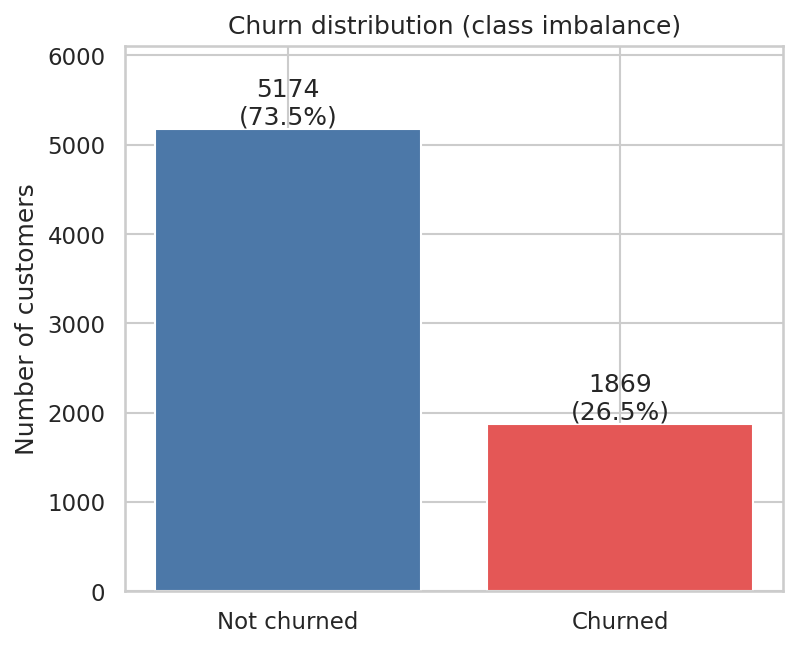

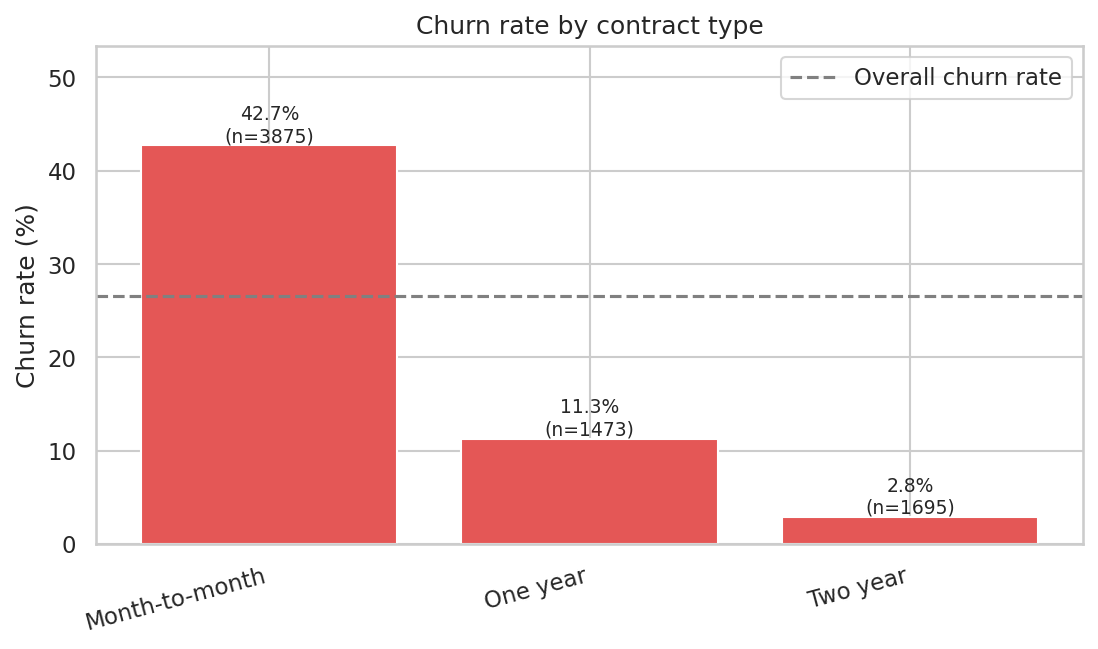

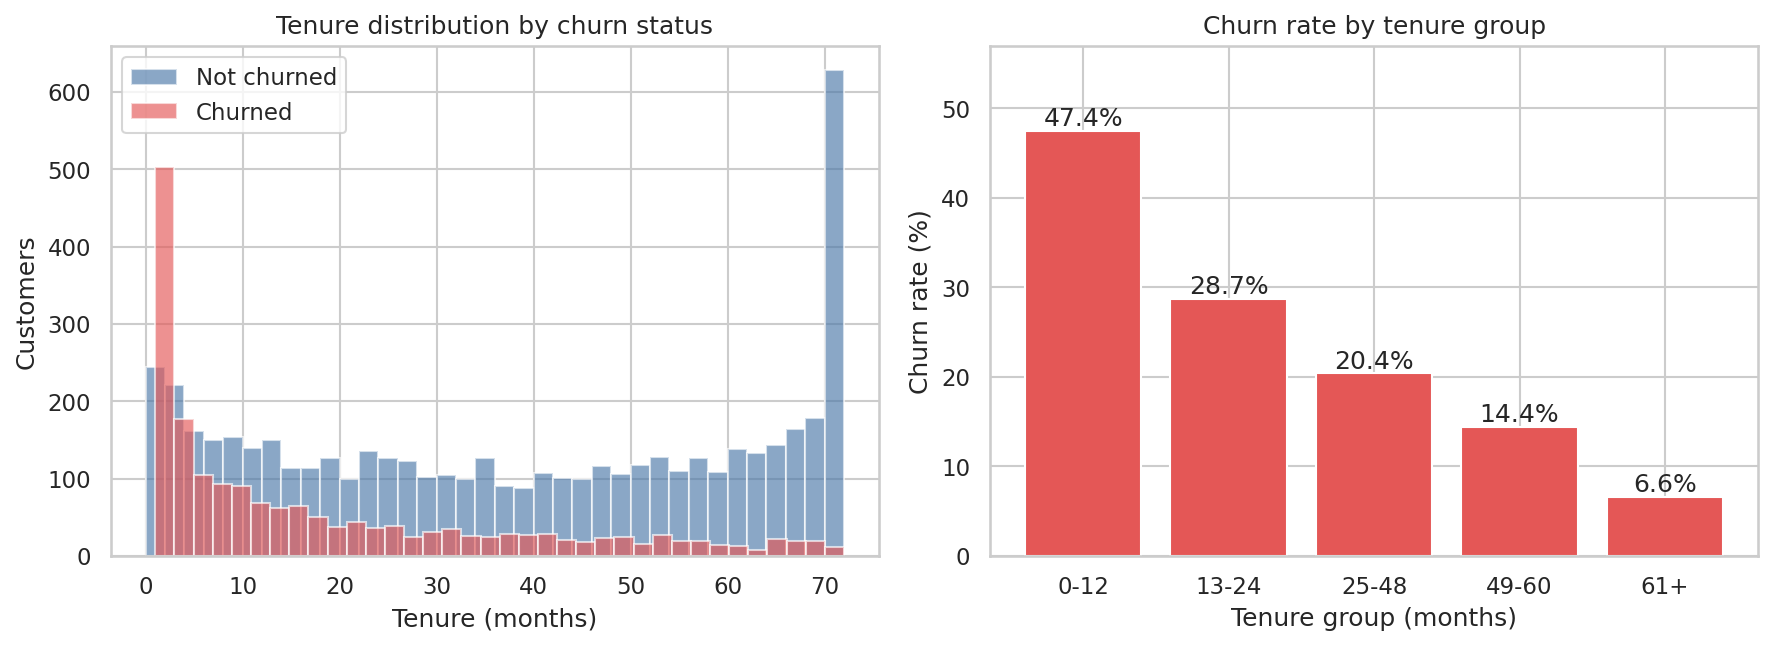

In [5]:
eda_plots.generate_all_eda_plots(df)
for f in ['01_churn_distribution', '02_contract_vs_churn', '03_tenure_vs_churn']:
    display(Image(str(config.FIGURES_DIR / f'{f}.png'), width=760))

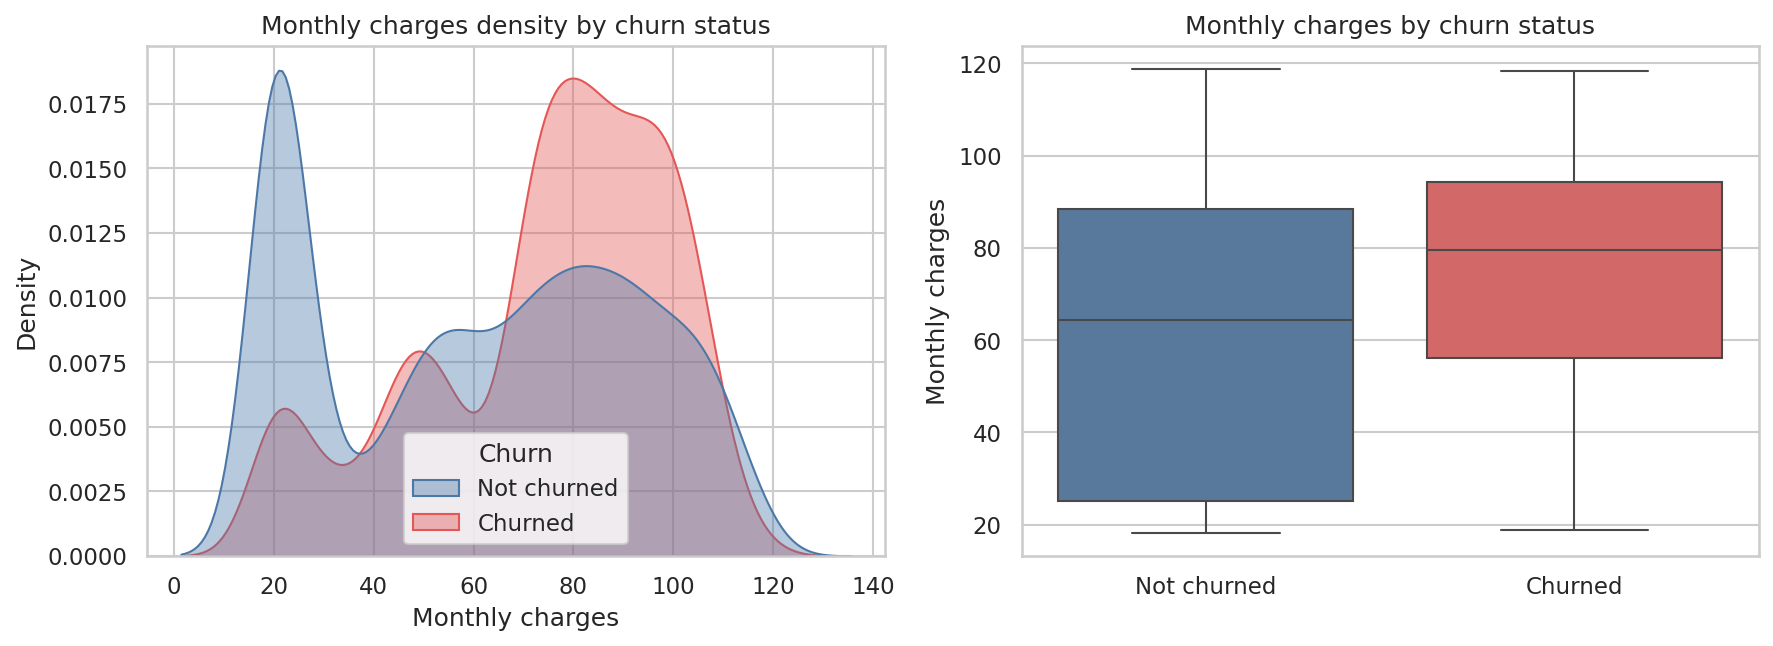

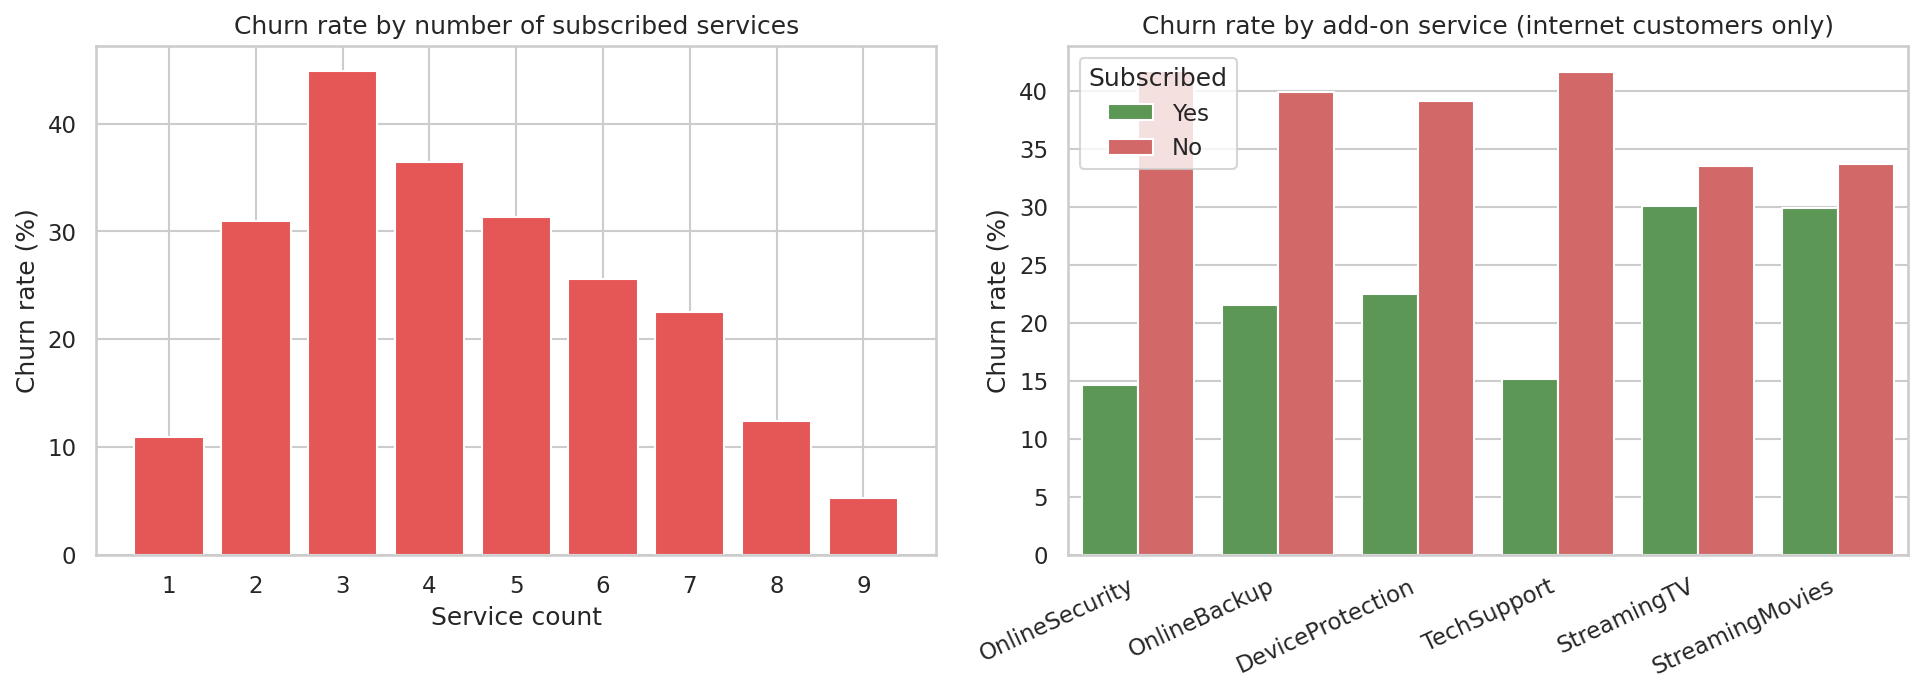

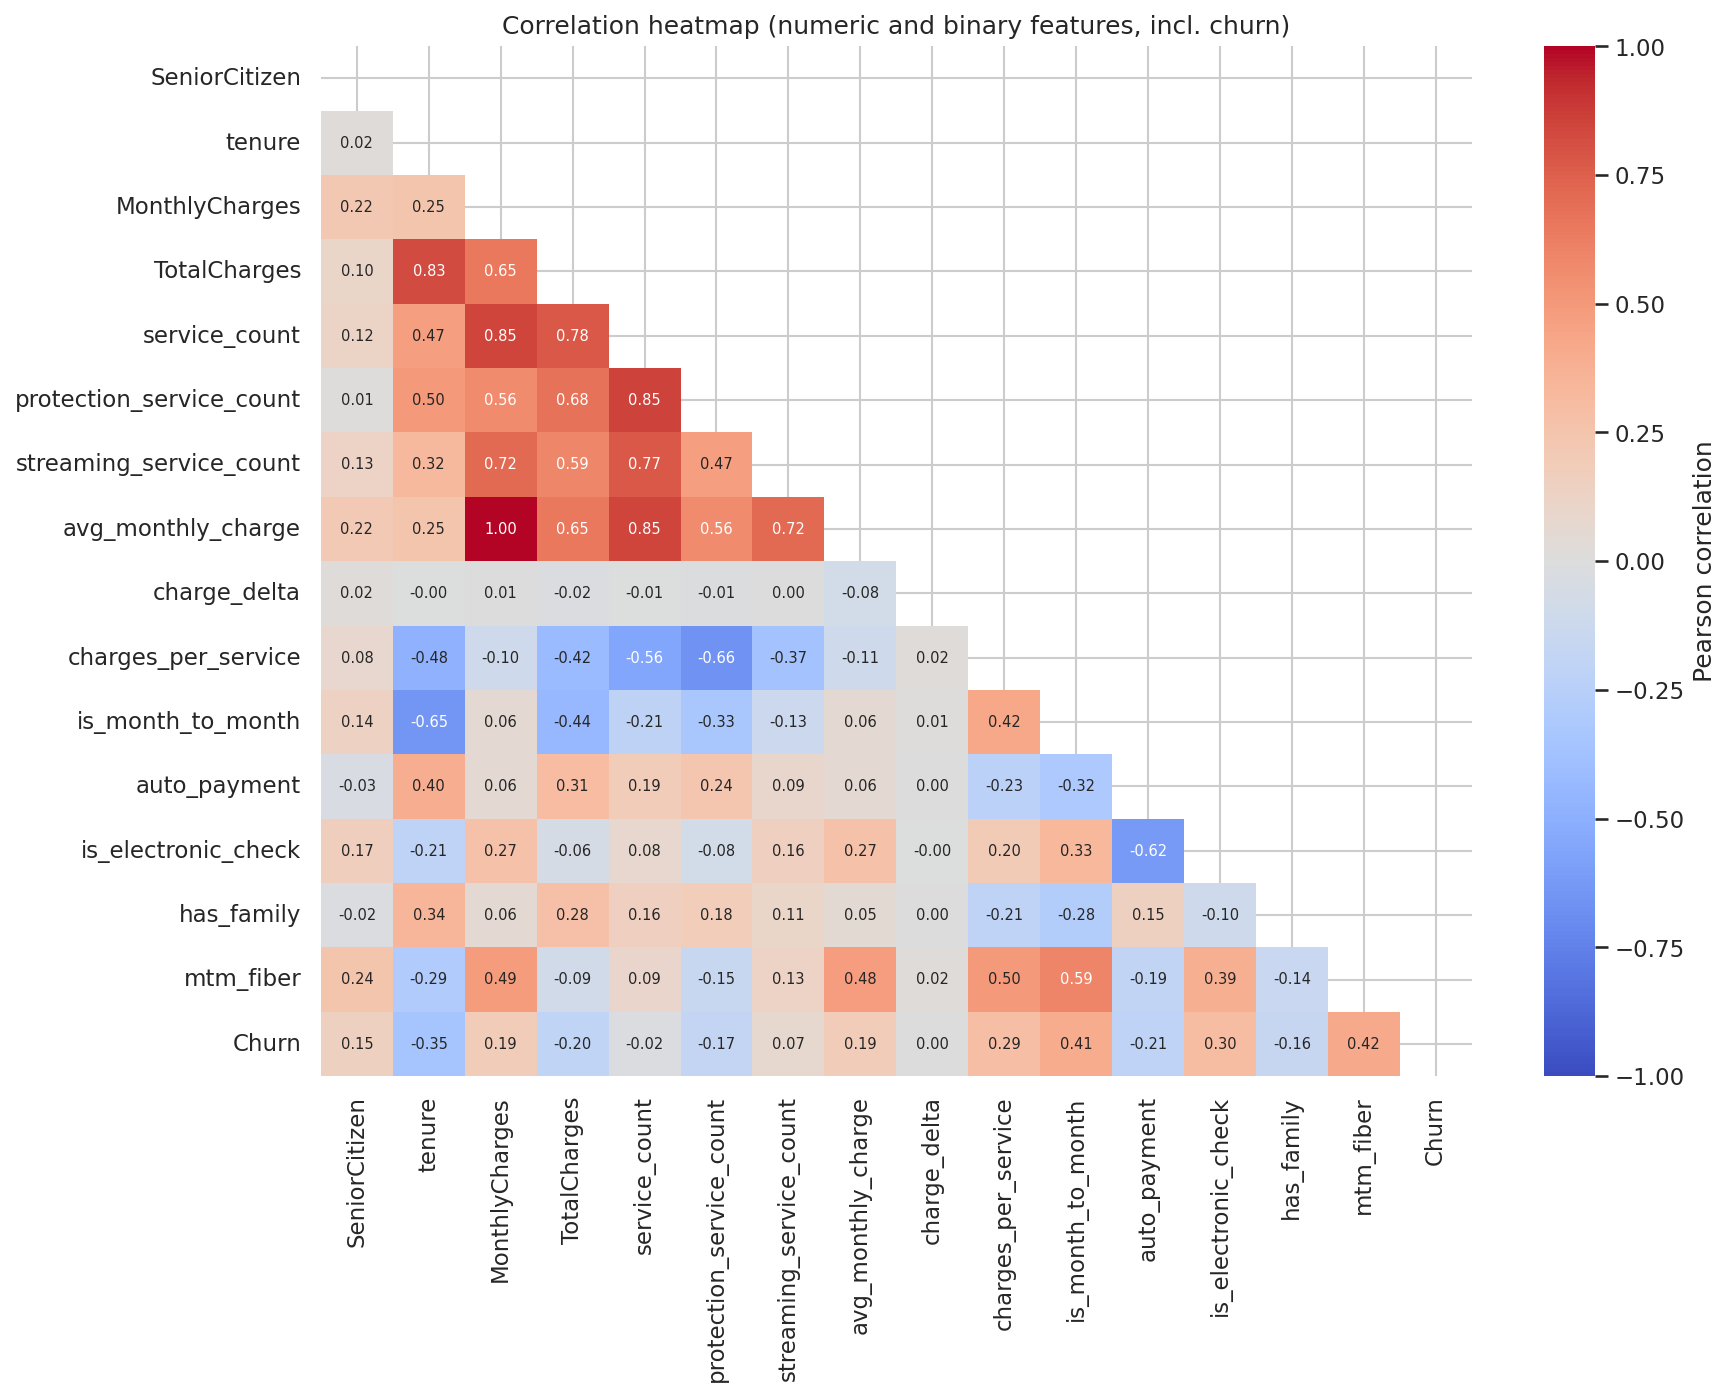

In [6]:
for f in ['04_monthly_charges_vs_churn', '05_services_vs_churn', '06_correlation_heatmap']:
    display(Image(str(config.FIGURES_DIR / f'{f}.png'), width=760))

In [7]:
for col in ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen', 'PaperlessBilling']:
    display(churn_rate_by(df, col).round(1))

,Contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


,InternetService,customers,churned,churn_rate_pct
0,DSL,2421,459,19.0
1,Fiber optic,3096,1297,41.9
2,No,1526,113,7.4


,PaymentMethod,customers,churned,churn_rate_pct
0,Bank transfer (automatic),1544,258,16.7
1,Credit card (automatic),1522,232,15.2
2,Electronic check,2365,1071,45.3
3,Mailed check,1612,308,19.1


,SeniorCitizen,customers,churned,churn_rate_pct
0,0,5901,1393,23.6
1,1,1142,476,41.7


,PaperlessBilling,customers,churned,churn_rate_pct
0,No,2872,469,16.3
1,Yes,4171,1400,33.6
